## 1. Imports and settings

In [1]:
#numpy pandas scipy scikit-learn matplotlib folium joblib
import json, time, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import folium
import joblib
import sklearn

from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.stats import norm

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

K_CAND = 10          # candidate roads kept per GPS observation
TRAIN_STRIDE = 5     # use every 5th GPS observation of a training trip for model fitting (speed)
FLAG_DIST_M = 50     # trip is flagged if its median GPS-to-reference-route distance exceeds this
CV_FOLDS = 5

# Only the three FastAPI handoff artifacts are saved here.
OUT = Path("pathsnap_output-1")
OUT.mkdir(exist_ok=True)
FEATURES = ["distance_m", "midpoint_distance_m", "segment_length_m", "speed_mps",
            "direction_difference", "distance_rank", "relative_distance_m"]

## 2. Locate the dataset
Keep the dataset ZIP next to this notebook (any `*.zip`) or set `ZIP_PATH`. If the data is already extracted into `pathsnap_data/`, the ZIP is not needed.

In [2]:
DATA_DIR = Path("./Student folder")  

def find_dirs(root):
    dirs = [p for p in root.rglob("*") if p.is_dir() and "__MACOSX" not in p.parts]

    train = [p for p in dirs if p.name.lower() == "train"]
    test = [p for p in dirs if "test" in p.name.lower() and "evaluator" not in p.name.lower()]

    return (train[0] if train else None), (test[0] if test else None)


TRAIN_DIR, STUDENT_TEST_DIR = find_dirs(DATA_DIR)

assert TRAIN_DIR is not None, "No 'train' folder found."
assert STUDENT_TEST_DIR is not None, "No student-test folder found."

print("Training folder    :", TRAIN_DIR)
print("Student-test folder:", STUDENT_TEST_DIR)


Training folder    : Student folder/train
Student-test folder: Student folder/student_test


## 3. Dataset inventory
Each trip folder holds `.track` (lon, lat, time), `.nodes` (lon, lat), `.arcs` (from_node, to_node; the row number is the `arc_id`) and `.route` (reference arc ids). Files are whitespace/tab separated without headers.

In [3]:
EXTS = [".track", ".nodes", ".arcs", ".route"]

def trip_folders(folder):
    return sorted(p for p in folder.iterdir() if p.is_dir() and (p / f"{p.name}.track").exists())

def inventory(folder, partition):
    rows = []
    for td in trip_folders(folder):
        row = {"partition": partition, "trip_id": td.name}
        for e in EXTS:
            f = td / f"{td.name}{e}"
            row[e + "_exists"] = f.exists()
            row[e + "_KB"] = round(f.stat().st_size / 1024, 1) if f.exists() else 0
        rows.append(row)
    return pd.DataFrame(rows)

inv = pd.concat([inventory(TRAIN_DIR, "train"), inventory(STUDENT_TEST_DIR, "student_test")], ignore_index=True)
print(inv.groupby("partition")["trip_id"].count().rename("trips").to_string())
print("Trips with a missing file:", int((~inv[[e + "_exists" for e in EXTS]].all(axis=1)).sum()))
display(inv.head())

partition
student_test    10
train           80
Trips with a missing file: 0


,partition,trip_id,.track_exists,.track_KB,.nodes_exists,.nodes_KB,.arcs_exists,.arcs_KB,.route_exists,.route_KB
0,train,00000001,True,40.0,True,1647.8,True,1902.8,True,3.0
1,train,00000002,True,232.5,True,155.0,True,152.9,True,1.4
2,train,00000003,True,25.6,True,178.5,True,171.6,True,0.4
3,train,00000004,True,34.2,True,143.6,True,146.2,True,1.5
4,train,00000005,True,32.6,True,17.5,True,12.1,True,0.4


## 4. Read raw files and clean the GPS track
Cleaning of `.track`: drop rows with missing / infinite / out-of-range coordinates, sort by time, drop duplicate timestamps. The raw quality counts are kept for the missing-value analysis.

In [4]:
def read_trip(td):
    tid = td.name
    raw = pd.read_csv(td / f"{tid}.track", sep=r"\s+", header=None, names=["lon", "lat", "time"])
    nodes = pd.read_csv(td / f"{tid}.nodes", sep=r"\s+", header=None, names=["lon", "lat"])
    arcs = pd.read_csv(td / f"{tid}.arcs", sep=r"\s+", header=None, names=["from_node", "to_node"])
    route = pd.read_csv(td / f"{tid}.route", sep=r"\s+", header=None, names=["arc_id"])["arc_id"].astype(int).tolist()

    quality = {"raw_rows": len(raw), "missing_values": int(raw.isna().sum().sum()),
               "unsorted_steps": int((raw["time"].diff() < 0).sum()),
               "duplicate_times": int(raw["time"].duplicated().sum())}
    track = raw.replace([np.inf, -np.inf], np.nan).dropna()
    track = track[track["lon"].between(-180, 180) & track["lat"].between(-90, 90)]
    track = track.sort_values("time").drop_duplicates("time").reset_index(drop=True)
    quality["rows_removed"] = len(raw) - len(track)
    return {"trip_id": tid, "track": track, "nodes": nodes, "arcs": arcs, "route": route, "quality": quality}

sample = read_trip(trip_folders(TRAIN_DIR)[0])
print("Sample trip:", sample["trip_id"])
for k in ["track", "nodes", "arcs"]:
    print(f"  {k}: {sample[k].shape}")
print("  reference route arcs:", len(sample["route"]))
display(sample["track"].head())

Sample trip: 00000001
  track: (1315, 3)
  nodes: (88809, 2)
  arcs: (165790, 2)
  reference route arcs: 525


,lon,lat,time
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


## 5. Geometry, candidate generation and features

In [5]:
def project_xy(lon, lat, lon0, lat0):
    x = np.radians(np.asarray(lon) - lon0) * 6371000.0 * np.cos(np.radians(lat0))
    y = np.radians(np.asarray(lat) - lat0) * 6371000.0
    return np.column_stack([x, y])

def segment_distance(P, A, B):
    V = B - A
    den = (V ** 2).sum(-1)
    den = np.where(den == 0, 1e-9, den)
    t = np.clip(((P - A) * V).sum(-1) / den, 0, 1)
    return np.linalg.norm(P - (A + t[..., None] * V), axis=-1)

def angle_diff(a, b):
    return np.abs((a - b + np.pi) % (2 * np.pi) - np.pi)

def trip_geometry(data):
    tr = data["track"]
    nodes = data["nodes"].to_numpy(float)
    arcs = data["arcs"].to_numpy(int)
    lon0, lat0 = tr["lon"].mean(), tr["lat"].mean()
    nxy = project_xy(nodes[:, 0], nodes[:, 1], lon0, lat0)
    return {"P": project_xy(tr["lon"], tr["lat"], lon0, lat0),
            "S": nxy[arcs[:, 0]], "E": nxy[arcs[:, 1]], "arcs": arcs}

def arc_sample_points(S, E, step=25.0):
    n = np.maximum(2, np.ceil(np.linalg.norm(E - S, axis=1) / step).astype(int) + 1)
    arc = np.repeat(np.arange(len(S)), n)
    first = np.cumsum(n) - n
    frac = (np.arange(n.sum()) - np.repeat(first, n)) / np.repeat(n - 1, n)
    return S[arc] + frac[:, None] * (E[arc] - S[arc]), arc

def generate_candidates(data, geom, k=K_CAND, probe=40):
    # Candidate roads + features for every GPS point. Uses NO route / label information.
    P, S, E, arcs = geom["P"], geom["S"], geom["E"], geom["arcs"]
    tr = data["track"]
    n = len(P)
    pts, arc_of_pt = arc_sample_points(S, E)
    _, idx = cKDTree(pts).query(P, k=min(probe, len(pts)))
    cand = np.sort(arc_of_pt[idx], axis=1)
    dup = np.zeros(cand.shape, bool)
    dup[:, 1:] = cand[:, 1:] == cand[:, :-1]
    dist = segment_distance(P[:, None, :], S[cand], E[cand])
    dist[dup] = np.inf                                   # an arc is kept only once per GPS point
    kk = min(k, cand.shape[1])
    order = np.argsort(dist, axis=1)[:, :kk]
    cand = np.take_along_axis(cand, order, 1)
    dist = np.take_along_axis(dist, order, 1)
    ok = np.isfinite(dist)

    t = tr["time"].to_numpy(float)
    prev = np.vstack([P[:1], P[:-1]])
    nxt = np.vstack([P[1:], P[-1:]])
    dt = np.maximum(np.diff(t, prepend=t[0]), 1.0)
    speed = np.linalg.norm(P - prev, axis=1) / dt
    move = nxt - prev
    moving = np.linalg.norm(move, axis=1) > 1.0
    gps_bearing = np.arctan2(move[:, 0], move[:, 1])
    seg_bearing = np.arctan2(E[:, 0] - S[:, 0], E[:, 1] - S[:, 1])
    ddiff = angle_diff(gps_bearing[:, None], seg_bearing[cand])
    ddiff[~moving, :] = np.pi / 2                       # heading unknown -> neutral value
    mid = (S + E) / 2
    seglen = np.linalg.norm(E - S, axis=1)
    obs = np.repeat(np.arange(n), kk).reshape(n, kk)
    return pd.DataFrame({
        "trip_id": data["trip_id"], "obs_index": obs[ok], "time": t[obs[ok]], "arc_id": cand[ok],
        "from_node": arcs[cand[ok], 0], "to_node": arcs[cand[ok], 1],
        "distance_m": dist[ok],
        "midpoint_distance_m": np.linalg.norm(P[:, None, :] - mid[cand], axis=-1)[ok],
        "segment_length_m": seglen[cand][ok],
        "speed_mps": np.repeat(speed, kk).reshape(n, kk)[ok],
        "direction_difference": ddiff[ok],
        "distance_rank": np.tile(np.arange(kk), (n, 1))[ok],
        "relative_distance_m": (dist - dist[:, :1])[ok]})

def reference_arcs(data, geom):
    # Approximate reference label: nearest arc (point-to-segment distance) among the supplied route arcs.
    route = np.unique(np.array(data["route"], dtype=int))
    d = segment_distance(geom["P"][:, None, :], geom["S"][route][None], geom["E"][route][None])
    return pd.DataFrame({"obs_index": np.arange(len(geom["P"])), "ref_arc": route[d.argmin(1)],
                         "ref_distance_m": d.min(1)})

def add_labels(cands, ref):
    out = cands.merge(ref[["obs_index", "ref_arc"]], on="obs_index", how="left")
    out["is_match"] = (out["arc_id"] == out["ref_arc"]).astype(int)
    return out

def top1_and_miss(frame, score):
    # Observation-level Top-1 accuracy and candidate miss rate. frame needs trip_id, obs_index, is_match.
    tmp = frame[["trip_id", "obs_index", "is_match"]].copy()
    tmp["score"] = np.asarray(score)
    best = tmp.loc[tmp.groupby(["trip_id", "obs_index"])["score"].idxmax()]
    has_ref = tmp.groupby(["trip_id", "obs_index"])["is_match"].max()
    return float(best["is_match"].mean()), float((has_ref == 0).mean())

## 6. Process every trip (EDA statistics + candidates + labels)
One pass per partition. For each trip we record data-quality, time-gap, extent, road-network connectivity (isolated nodes, connected components), route structure and how far the GPS trace is from the reference route.

In [6]:
def trip_eda(data, geom, ref):
    tr, arcs, P = data["track"], geom["arcs"], geom["P"]
    gaps = tr["time"].diff().dropna()
    n_nodes = len(data["nodes"])
    adj = coo_matrix((np.ones(len(arcs)), (arcs[:, 0], arcs[:, 1])), shape=(n_nodes, n_nodes))
    n_comp, labels = connected_components(adj, directed=False)
    used = np.zeros(n_nodes, bool); used[arcs.ravel()] = True
    route = np.array(data["route"])
    route_ok = float(np.mean(arcs[route[:-1], 1] == arcs[route[1:], 0])) if len(route) > 1 else np.nan
    row = {"trip_id": data["trip_id"], "gps_points": len(tr), **data["quality"],
           "median_gap_s": float(gaps.median()), "max_gap_s": float(gaps.max()),
           "share_1s_steps": float((gaps == 1).mean()), "gaps_over_10s": int((gaps > 10).sum()),
           "extent_x_km": float(np.ptp(P[:, 0]) / 1000), "extent_y_km": float(np.ptp(P[:, 1]) / 1000),
           "road_nodes": n_nodes, "road_arcs": len(arcs), "isolated_nodes": int((~used).sum()),
           "components": int(n_comp), "largest_component_share": float(np.bincount(labels).max() / n_nodes),
           "route_arcs": len(route), "route_connected_share": route_ok,
           "median_ref_dist_m": float(ref["ref_distance_m"].median())}
    row["flagged"] = row["median_ref_dist_m"] > FLAG_DIST_M
    return row

def process_partition(folder, name):
    frames, rows, store = [], [], {}
    t0 = time.time()
    for td in trip_folders(folder):
        data = read_trip(td)
        geom = trip_geometry(data)
        ref = reference_arcs(data, geom)
        frames.append(add_labels(generate_candidates(data, geom), ref))
        rows.append(trip_eda(data, geom, ref))
        store[data["trip_id"]] = {"arcs": geom["arcs"], "route": data["route"],
                                  "ref": ref.set_index("obs_index")["ref_arc"]}
    print(f"{name}: {len(rows)} trips processed in {time.time() - t0:.0f}s")
    return pd.concat(frames, ignore_index=True), pd.DataFrame(rows), store

train_all, eda_train, store_train = process_partition(TRAIN_DIR, "train")
test_all, eda_test, store_test = process_partition(STUDENT_TEST_DIR, "student_test")

train: 80 trips processed in 7s
student_test: 10 trips processed in 0s


### 6.1 Data-quality summary

In [7]:
for name, e in [("TRAIN", eda_train), ("STUDENT-TEST", eda_test)]:
    print(f"===== {name}: {len(e)} trips =====")
    cols = ["gps_points", "missing_values", "rows_removed", "unsorted_steps", "duplicate_times", "max_gap_s",
            "share_1s_steps", "gaps_over_10s", "road_nodes", "road_arcs", "isolated_nodes", "components",
            "route_arcs", "route_connected_share", "median_ref_dist_m"]
    display(e[cols].describe().T[["min", "50%", "max"]].round(3))
    print("Total missing values:", int(e["missing_values"].sum()),
          "| total rows removed by cleaning:", int(e["rows_removed"].sum()))
    print("Flagged trips (median GPS-to-reference-route distance >", FLAG_DIST_M, "m):",
          e.loc[e["flagged"], "trip_id"].tolist())

===== TRAIN: 80 trips =====


,min,50%,max
gps_points,361.000,1529.000,19313.000
missing_values,0.000,0.000,0.000
rows_removed,0.000,0.000,0.000
unsorted_steps,0.000,0.000,0.000
duplicate_times,0.000,0.000,0.000
max_gap_s,1.000,11.000,153064.000
share_1s_steps,0.531,0.991,1.000
gaps_over_10s,0.000,0.500,215.000
road_nodes,299.000,9608.000,155003.000
road_arcs,649.000,19526.500,307392.000


Total missing values: 0 | total rows removed by cleaning: 0
Flagged trips (median GPS-to-reference-route distance > 50 m): ['00000033', '00000054']
===== STUDENT-TEST: 10 trips =====


,min,50%,max
gps_points,262.000,1420.000,3958.000
missing_values,0.000,0.000,0.000
rows_removed,0.000,0.000,0.000
unsorted_steps,0.000,0.000,0.000
duplicate_times,0.000,0.000,0.000
max_gap_s,1.000,2.000,210.000
share_1s_steps,0.861,0.999,1.000
gaps_over_10s,0.000,0.000,24.000
road_nodes,1770.000,6596.500,26635.000
road_arcs,3577.000,13145.000,56027.000


Total missing values: 0 | total rows removed by cleaning: 0
Flagged trips (median GPS-to-reference-route distance > 50 m): []


### 6.2 Exploration plots (GPS counts, time gaps, trajectories, road network)

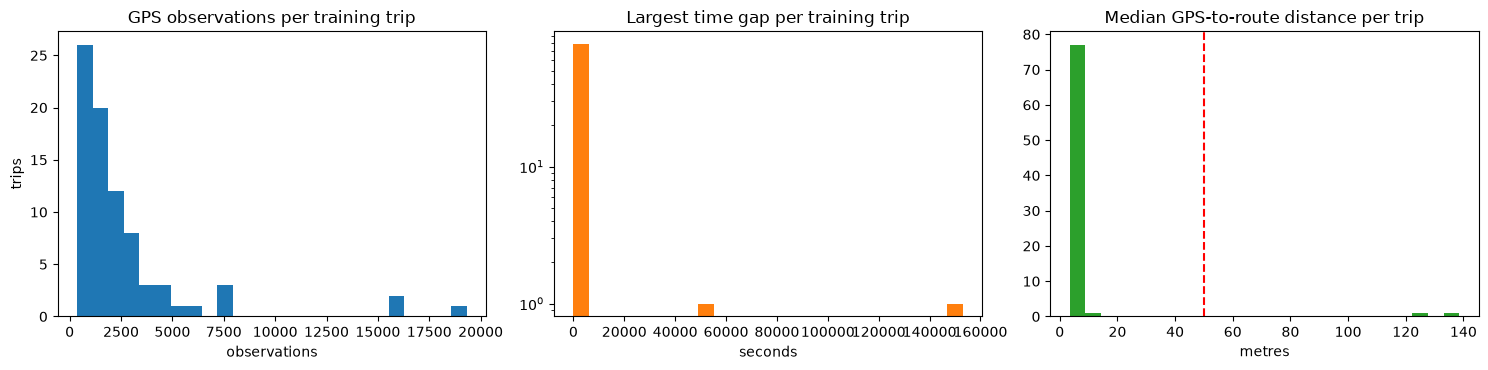

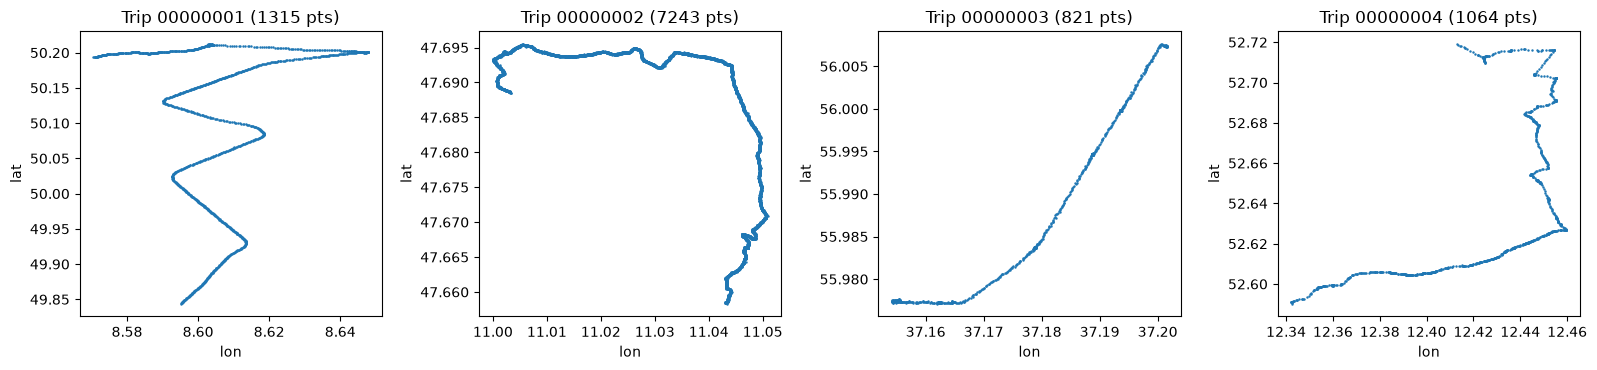

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(eda_train["gps_points"], bins=25); ax[0].set_title("GPS observations per training trip")
ax[0].set_xlabel("observations"); ax[0].set_ylabel("trips")
ax[1].hist(eda_train["max_gap_s"], bins=25, color="tab:orange"); ax[1].set_yscale("log")
ax[1].set_title("Largest time gap per training trip"); ax[1].set_xlabel("seconds")
ax[2].hist(eda_train["median_ref_dist_m"], bins=25, color="tab:green")
ax[2].axvline(FLAG_DIST_M, color="red", ls="--"); ax[2].set_title("Median GPS-to-route distance per trip")
ax[2].set_xlabel("metres")
plt.tight_layout(); plt.show()

# Trajectories of four training trips (longitude / latitude)
ids = list(eda_train["trip_id"][:4])
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, tid in zip(ax, ids):
    tr = read_trip(TRAIN_DIR / tid)["track"]
    a.plot(tr["lon"], tr["lat"], ".", ms=1.5); a.set_title(f"Trip {tid} ({len(tr)} pts)")
    a.set_xlabel("lon"); a.set_ylabel("lat")
plt.tight_layout(); plt.show()

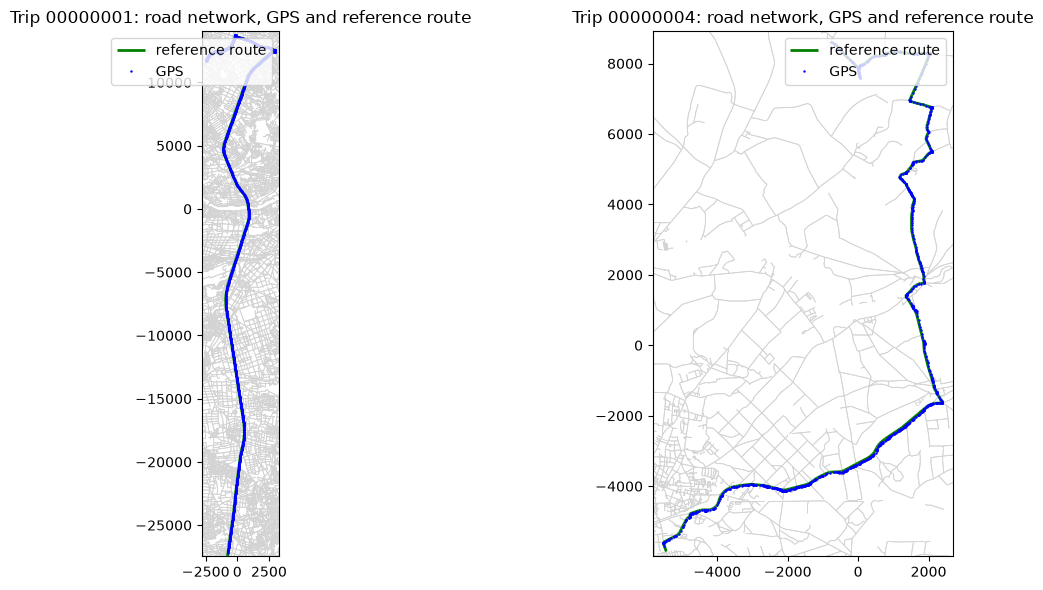

In [9]:
from matplotlib.collections import LineCollection

def plot_network(trip_dir, ax, pad_m=300):
    d = read_trip(trip_dir); g = trip_geometry(d)
    P, S, E = g["P"], g["S"], g["E"]
    lo, hi = P.min(0) - pad_m, P.max(0) + pad_m
    inside = ((S > lo) & (S < hi)).all(1) | ((E > lo) & (E < hi)).all(1)
    segs = np.stack([S[inside], E[inside]], axis=1)
    ax.add_collection(LineCollection(segs, colors="lightgrey", linewidths=0.6))
    r = np.array(d["route"])
    ax.add_collection(LineCollection(np.stack([S[r], E[r]], axis=1), colors="green", linewidths=2, label="reference route"))
    ax.plot(P[:, 0], P[:, 1], "b.", ms=1.5, label="GPS")
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_aspect("equal")
    ax.set_title(f"Trip {d['trip_id']}: road network, GPS and reference route"); ax.legend(loc="upper right")

good = eda_train.loc[~eda_train["flagged"], "trip_id"].tolist()
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
plot_network(TRAIN_DIR / good[0], ax[0]); plot_network(TRAIN_DIR / good[min(3, len(good) - 1)], ax[1])
plt.tight_layout(); plt.show()

## 7. Training and student-test tables
Training rows come from the non-flagged training trips, using every `TRAIN_STRIDE`-th GPS observation (keeps the five models and Bayesian search fast; the sampled rows still cover every trip). The **student-test table keeps every observation**, so Top-1, candidate-miss and route continuity are computed on complete trips.

In [10]:
flagged_train = set(eda_train.loc[eda_train["flagged"], "trip_id"])
train_tbl = train_all[~train_all["trip_id"].isin(flagged_train) & (train_all["obs_index"] % TRAIN_STRIDE == 0)].reset_index(drop=True)
test_tbl = test_all.reset_index(drop=True)

X_train, y_train, g_train = train_tbl[FEATURES], train_tbl["is_match"], train_tbl["trip_id"]
X_test, y_test = test_tbl[FEATURES], test_tbl["is_match"]

_, miss_train = top1_and_miss(train_all[~train_all["trip_id"].isin(flagged_train)], np.zeros((~train_all["trip_id"].isin(flagged_train)).sum()))
_, miss_test = top1_and_miss(test_tbl, np.zeros(len(test_tbl)))
print(f"Training rows: {len(train_tbl):,} from {g_train.nunique()} trips "
      f"({len(flagged_train)} flagged trips excluded) | positive rate {y_train.mean():.3f}")
print(f"Student-test rows: {len(test_tbl):,} from {test_tbl['trip_id'].nunique()} trips | positive rate {y_test.mean():.3f}")
print(f"Candidate miss rate  - training trips (flagged excluded): {miss_train:.4f} | student-test trips: {miss_test:.4f}")
assert set(train_tbl["trip_id"]).isdisjoint(set(test_tbl["trip_id"])), "trip leaked across partitions"
display(train_tbl[["trip_id", "obs_index", "arc_id"] + FEATURES + ["is_match"]].head())

Training rows: 331,728 from 78 trips (2 flagged trips excluded) | positive rate 0.110
Student-test rows: 170,774 from 10 trips | positive rate 0.112
Candidate miss rate  - training trips (flagged excluded): 0.0065 | student-test trips: 0.0008


,trip_id,obs_index,arc_id,distance_m,midpoint_distance_m,segment_length_m,speed_mps,direction_difference,distance_rank,relative_distance_m,is_match
0,00000001,0,64973,0.717461,114.427571,293.233070,0.0,0.022749,0,0.000000,1
1,00000001,0,117639,15.011181,19.845798,1020.418564,0.0,3.120038,1,14.293720,0
2,00000001,0,2641,32.199208,244.716045,425.044898,0.0,0.024998,2,31.481746,0
3,00000001,0,53932,92.292524,109.239935,169.056399,0.0,0.205093,3,91.575063,0
4,00000001,0,50652,92.292524,109.239935,169.056399,0.0,2.936500,4,91.575063,0


## 8. Compare five models
All five output a match probability for every candidate road, so the HMM can use them later.

* **Primary selection metric: CV Macro-F1** (group 5-fold CV on the training trips, each trip kept in one fold). Macro-F1 is used because only ~10 % of candidates are positives, so accuracy alone is misleading. CV log-loss is the second criterion (probability quality matters because the HMM uses the probabilities).
* Scaling/imputation are inside the pipelines, so they are fitted on training folds only.
* The student-test set is **not** used to pick the final model.

In [11]:
models = {
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "K-Nearest Neighbours": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
        KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1)),
    "Decision Tree": make_pipeline(SimpleImputer(strategy="median"),
        DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=5, class_weight="balanced",
                               n_jobs=-1, random_state=RANDOM_STATE)),
    "Hist Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_depth=6, early_stopping=False,
                                       random_state=RANDOM_STATE)),
}
model_info = pd.DataFrame([
    ("Logistic Regression", "Linear / probabilistic", "C=1.0, L2, balanced class weight, standardised", "Log loss (cross-entropy)"),
    ("K-Nearest Neighbours", "Instance-based", "k=15, distance-weighted, standardised", "None (distance-weighted vote)"),
    ("Decision Tree", "Tree-based", "max_depth=10, min_samples_leaf=20, balanced", "Gini impurity"),
    ("Random Forest", "Ensemble (bagging)", "100 trees, max_depth=14, min_samples_leaf=5, balanced", "Gini impurity per tree"),
    ("Hist Gradient Boosting", "Boosting", "150 iters, lr=0.1, max_depth=6", "Log loss (gradient boosted)"),
], columns=["Model", "Algorithm family", "Key configuration", "Objective"]).set_index("Model")

cv = GroupKFold(n_splits=CV_FOLDS)
fitted, cv_rows, test_scores, test_rows = {}, [], {}, []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, groups=g_train, cv=cv, n_jobs=1, return_train_score=True,
                         scoring={"f1": "f1_macro", "ll": "neg_log_loss"})
    t0 = time.time(); model.fit(X_train, y_train); fit_s = time.time() - t0
    t0 = time.time(); p = model.predict_proba(X_test)[:, 1]; inf_s = time.time() - t0
    fitted[name], test_scores[name] = model, p
    pred = (p >= 0.5).astype(int)
    top1, miss = top1_and_miss(test_tbl, p)
    cv_rows.append({"Model": name, "CV_Macro_F1": res["test_f1"].mean(), "CV_F1_std": res["test_f1"].std(),
                    "CV_Log_Loss": -res["test_ll"].mean(), "Train_Macro_F1": res["train_f1"].mean(),
                    "Fit_time_s": fit_s})
    test_rows.append({"Model": name, "Test_Accuracy": accuracy_score(y_test, pred),
                      "Test_Precision": precision_score(y_test, pred, zero_division=0),
                      "Test_Recall": recall_score(y_test, pred, zero_division=0),
                      "Test_Macro_F1": f1_score(y_test, pred, average="macro"),
                      "Test_Log_Loss": log_loss(y_test, np.clip(p, 1e-6, 1 - 1e-6)),
                      "Top1_Accuracy": top1, "Candidate_Miss_Rate": miss, "Inference_time_s": inf_s})
    print(f"{name:24s} CV Macro-F1 {cv_rows[-1]['CV_Macro_F1']:.4f} | fit {fit_s:.1f}s")

Logistic Regression      CV Macro-F1 0.8027 | fit 0.3s
K-Nearest Neighbours     CV Macro-F1 0.8866 | fit 0.2s
Decision Tree            CV Macro-F1 0.8450 | fit 1.3s
Random Forest            CV Macro-F1 0.8685 | fit 3.3s
Hist Gradient Boosting   CV Macro-F1 0.8948 | fit 1.3s


**Route continuity** (classifier-only) is the share of consecutive *different* arcs in the predicted route where the next arc starts at the previous arc's end node. Repeated arcs are collapsed first, because a vehicle stays on one arc for several 1 Hz observations.

In [12]:
def route_continuity(seq, arcs):
    seq = [int(a) for i, a in enumerate(seq) if i == 0 or a != seq[i - 1]]
    if len(seq) < 2:
        return np.nan
    ok = sum(int(arcs[a][1]) == int(arcs[b][0]) for a, b in zip(seq[:-1], seq[1:]))
    return ok / (len(seq) - 1)

def arc_set_scores(pred, ref):
    p, r = set(map(int, pred)), set(map(int, ref))
    tp = len(p & r)
    prec = tp / len(p) if p else 0.0
    rec = tp / len(r) if r else 0.0
    return prec, rec, (2 * prec * rec / (prec + rec) if prec + rec else 0.0)

def classifier_only_routes(frame, scores):
    # best-scoring candidate for every GPS observation, returned per trip
    tmp = frame[["trip_id", "obs_index", "arc_id"]].copy(); tmp["score"] = np.asarray(scores)
    best = tmp.loc[tmp.groupby(["trip_id", "obs_index"])["score"].idxmax()].sort_values(["trip_id", "obs_index"])
    return {tid: part for tid, part in best.groupby("trip_id")}

def mean_continuity(frame, scores):
    routes = classifier_only_routes(frame, scores)
    return float(np.nanmean([route_continuity(r["arc_id"].tolist(), store_test[t]["arcs"]) for t, r in routes.items()]))

for row in test_rows:
    row["Route_Continuity"] = mean_continuity(test_tbl, test_scores[row["Model"]])

comparison = (model_info.reset_index()
              .merge(pd.DataFrame(cv_rows), on="Model").merge(pd.DataFrame(test_rows), on="Model").set_index("Model"))
table_cols = ["Algorithm family", "Key configuration", "CV_Macro_F1", "Top1_Accuracy", "Route_Continuity",
              "Test_Macro_F1", "Test_Log_Loss", "Inference_time_s"]
display(comparison[table_cols].round(4))
display(comparison[["Objective", "Train_Macro_F1", "CV_Macro_F1", "CV_F1_std", "Test_Macro_F1", "CV_Log_Loss",
                    "Test_Precision", "Test_Recall", "Test_Accuracy", "Candidate_Miss_Rate", "Fit_time_s"]].round(4))

,Algorithm family,Key configuration,CV_Macro_F1,Top1_Accuracy,Route_Continuity,Test_Macro_F1,Test_Log_Loss,Inference_time_s
Model,,,,,,,,
Logistic Regression,Linear / probabilistic,"C=1.0, L2, balanced class weight, standardised",0.8027,0.8290,0.7110,0.7937,0.2291,0.0050
K-Nearest Neighbours,Instance-based,"k=15, distance-weighted, standardised",0.8866,0.8231,0.6996,0.8928,0.1736,1.1995
Decision Tree,Tree-based,"max_depth=10, min_samples_leaf=20, balanced",0.8450,0.8308,0.7157,0.8530,0.1873,0.0082
Random Forest,Ensemble (bagging),"100 trees, max_depth=14, min_samples_leaf=5, b...",0.8685,0.8295,0.7101,0.8716,0.1601,0.0881
Hist Gradient Boosting,Boosting,"150 iters, lr=0.1, max_depth=6",0.8948,0.8303,0.7156,0.9010,0.1015,0.1036


,Objective,Train_Macro_F1,CV_Macro_F1,CV_F1_std,Test_Macro_F1,CV_Log_Loss,Test_Precision,Test_Recall,Test_Accuracy,Candidate_Miss_Rate,Fit_time_s
Model,,,,,,,,,,,
Logistic Regression,Log loss (cross-entropy),0.8032,0.8027,0.0106,0.7937,0.2179,0.5021,0.9366,0.8888,0.0008,0.3032
K-Nearest Neighbours,None (distance-weighted vote),1.0000,0.8866,0.0084,0.8928,0.3095,0.8163,0.8027,0.9576,0.0008,0.2398
Decision Tree,Gini impurity,0.8559,0.8450,0.0096,0.8530,0.2269,0.6254,0.9273,0.9296,0.0008,1.3366
Random Forest,Gini impurity per tree,0.8948,0.8685,0.0113,0.8716,0.1571,0.6737,0.9180,0.9410,0.0008,3.3238
Hist Gradient Boosting,Log loss (gradient boosted),0.9053,0.8948,0.0087,0.9010,0.1047,0.8376,0.8106,0.9612,0.0008,1.3287


Overfitting check: a large gap between `Train_Macro_F1` and `CV_Macro_F1` signals overfitting; low values on both signal underfitting. Confusion matrices below are candidate-level on the student-test trips (threshold 0.5).

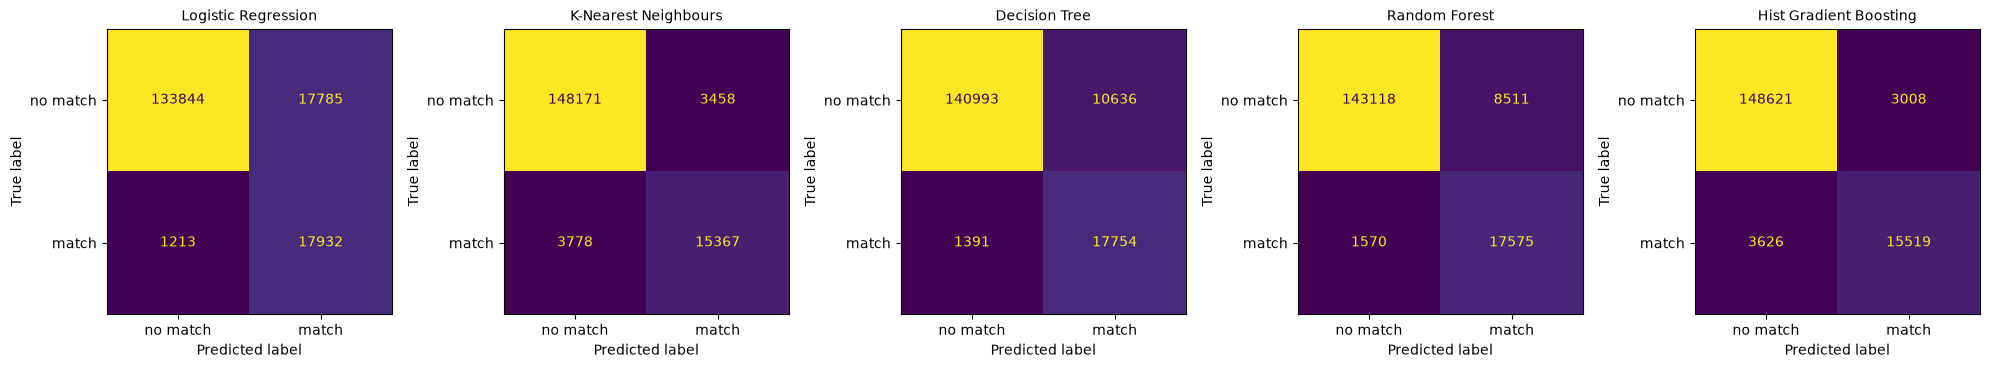

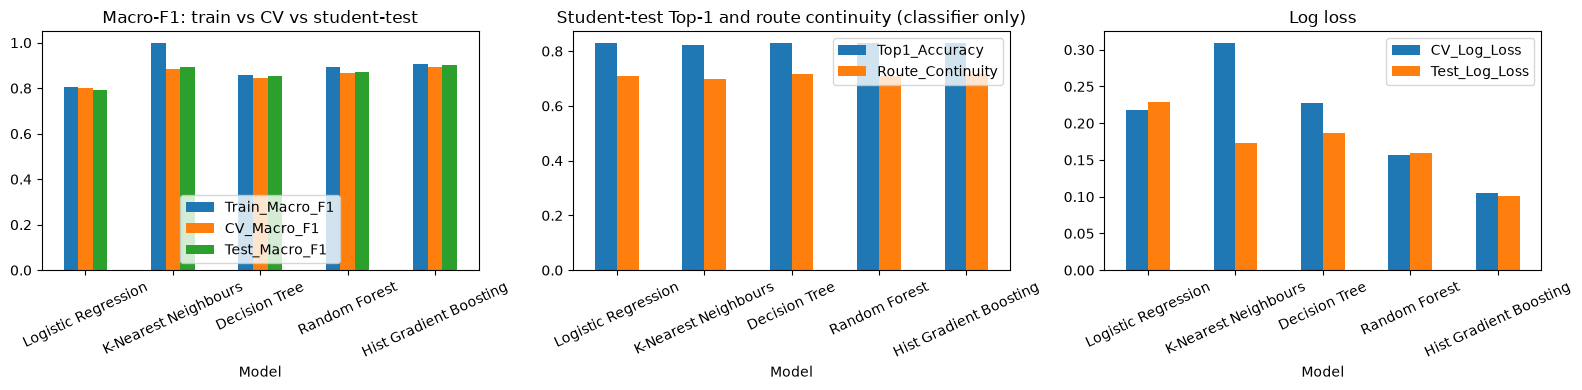

In [13]:
fig, ax = plt.subplots(1, 5, figsize=(20, 3.8))
for a, (name, p) in zip(ax, test_scores.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= 0.5).astype(int)), display_labels=["no match", "match"]).plot(ax=a, colorbar=False)
    a.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
comparison[["Train_Macro_F1", "CV_Macro_F1", "Test_Macro_F1"]].plot.bar(ax=ax[0], rot=25); ax[0].set_title("Macro-F1: train vs CV vs student-test")
comparison[["Top1_Accuracy", "Route_Continuity"]].plot.bar(ax=ax[1], rot=25); ax[1].set_title("Student-test Top-1 and route continuity (classifier only)")
comparison[["CV_Log_Loss", "Test_Log_Loss"]].plot.bar(ax=ax[2], rot=25); ax[2].set_title("Log loss")
plt.tight_layout(); plt.show()

## 9. Bayesian hyperparameter optimisation (Gaussian process + Expected Improvement)
Gradient boosting is tuned: it is a strong, fast, probability-based model that suits the HMM.

* **Search space:** learning rate (log scale 0.02–0.3), iterations 50–300, tree depth 3–12, minimum samples per leaf 10–200, L2 regularisation 0–2.
* **Objective:** maximise mean **CV Macro-F1** over `GroupKFold` on the training trips (same folds as section 8).
* **Method:** 6 random initial trials, then each new trial maximises Expected Improvement under a Gaussian-process surrogate (Matérn kernel) fitted to all previous trials. Every trial is recorded.
* The student-test set is not used in the search.

In [14]:
SPACE = {  # name: (low, high, kind)
    "learning_rate": (0.02, 0.3, "log"), "max_iter": (50, 300, "int"), "max_depth": (3, 12, "int"),
    "min_samples_leaf": (10, 200, "int"), "l2_regularization": (0.0, 2.0, "float")}
N_INITIAL, N_BAYES = 6, 14
names = list(SPACE)

def decode(u):
    params = {}
    for x, name in zip(u, names):
        lo, hi, kind = SPACE[name]
        if kind == "log":
            params[name] = float(np.exp(np.log(lo) + x * (np.log(hi) - np.log(lo))))
        elif kind == "int":
            params[name] = int(round(lo + x * (hi - lo)))
        else:
            params[name] = float(lo + x * (hi - lo))
    return params

def make_hgb(params):
    return make_pipeline(SimpleImputer(strategy="median"),
                         HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE, **params))

def objective(u):
    t0 = time.time()
    params = decode(u)
    res = cross_validate(make_hgb(params), X_train, y_train, groups=g_train, cv=cv, scoring="f1_macro", n_jobs=1)
    return res["test_score"].mean(), res["test_score"].std(), time.time() - t0

def expected_improvement(gp, cand, best):
    mu, sd = gp.predict(cand, return_std=True)
    sd = np.maximum(sd, 1e-9)
    z = (mu - best) / sd
    return (mu - best) * norm.cdf(z) + sd * norm.pdf(z)

rng = np.random.RandomState(RANDOM_STATE)
U, scores, trials = [], [], []
t_bo = time.time()
for trial in range(N_INITIAL + N_BAYES):
    if trial < N_INITIAL:
        u = rng.rand(len(names)); how = "random"
    else:
        gp = GaussianProcessRegressor(kernel=Matern(nu=2.5) + WhiteKernel(1e-3), normalize_y=True,
                                      n_restarts_optimizer=3, random_state=RANDOM_STATE)
        gp.fit(np.array(U), np.array(scores))
        pool = rng.rand(3000, len(names))
        u = pool[np.argmax(expected_improvement(gp, pool, max(scores)))]; how = "bayesian (EI)"
    score, std, secs = objective(u)
    U.append(u); scores.append(score)
    trials.append({"trial": trial + 1, "method": how, "cv_macro_f1": score, "cv_std": std, "seconds": secs, **decode(u)})
    print(f"trial {trial + 1:2d} [{how:13s}] CV Macro-F1 {score:.4f}  {decode(u)}")

bo_trials = pd.DataFrame(trials)
best_params = decode(U[int(np.argmax(scores))])
bo_seconds = time.time() - t_bo
print("\nBest CV Macro-F1:", round(max(scores), 4), "\nBest parameters:", best_params, f"\nSearch time: {bo_seconds:.0f}s")

trial  1 [random       ] CV Macro-F1 0.8952  {'learning_rate': 0.05514718587869894, 'max_iter': 288, 'max_depth': 10, 'min_samples_leaf': 124, 'l2_regularization': 0.31203728088487304}
trial  2 [random       ] CV Macro-F1 0.8912  {'learning_rate': 0.03051362379613698, 'max_iter': 65, 'max_depth': 11, 'min_samples_leaf': 124, 'l2_regularization': 1.416145155592091}
trial  3 [random       ] CV Macro-F1 0.8954  {'learning_rate': 0.021146536167031597, 'max_iter': 292, 'max_depth': 10, 'min_samples_leaf': 50, 'l2_regularization': 0.36364993441420124}
trial  4 [random       ] CV Macro-F1 0.8949  {'learning_rate': 0.03286475783941524, 'max_iter': 126, 'max_depth': 8, 'min_samples_leaf': 92, 'l2_regularization': 0.5824582803960838}
trial  5 [random       ] CV Macro-F1 0.8956  {'learning_rate': 0.10486361783805698, 'max_iter': 85, 'max_depth': 6, 'min_samples_leaf': 80, 'l2_regularization': 0.9121399684340719}
trial  6 [random       ] CV Macro-F1 0.8952  {'learning_rate': 0.16767510257004176, '

/Users/charith/Desktop/ML/ML_Hackathon_team_10/.venv/lib/python3.15/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


trial  7 [bayesian (EI)] CV Macro-F1 0.8952  {'learning_rate': 0.1538813788517412, 'max_iter': 83, 'max_depth': 8, 'min_samples_leaf': 114, 'l2_regularization': 0.17894624562077444}


/Users/charith/Desktop/ML/ML_Hackathon_team_10/.venv/lib/python3.15/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


trial  8 [bayesian (EI)] CV Macro-F1 0.8951  {'learning_rate': 0.06273118177562108, 'max_iter': 135, 'max_depth': 4, 'min_samples_leaf': 52, 'l2_regularization': 0.44754458316170687}


/Users/charith/Desktop/ML/ML_Hackathon_team_10/.venv/lib/python3.15/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


... (19 outputs left out)

/Users/charith/Desktop/ML/ML_Hackathon_team_10/.venv/lib/python3.15/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


trial 19 [bayesian (EI)] CV Macro-F1 0.8956  {'learning_rate': 0.03503766977065669, 'max_iter': 296, 'max_depth': 9, 'min_samples_leaf': 31, 'l2_regularization': 1.128163980292913}


/Users/charith/Desktop/ML/ML_Hackathon_team_10/.venv/lib/python3.15/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


trial 20 [bayesian (EI)] CV Macro-F1 0.8861  {'learning_rate': 0.2837430776624578, 'max_iter': 298, 'max_depth': 11, 'min_samples_leaf': 12, 'l2_regularization': 0.016498677414222396}

Best CV Macro-F1: 0.8957 
Best parameters: {'learning_rate': 0.028528226096179724, 'max_iter': 300, 'max_depth': 9, 'min_samples_leaf': 28, 'l2_regularization': 0.6567974754068311} 
Search time: 172s


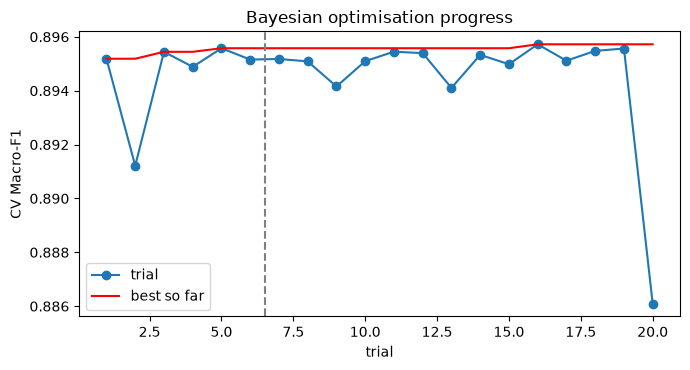

,CV_Macro_F1,CV_Log_Loss,Test_Macro_F1,Test_Log_Loss,Top1_Accuracy,Route_Continuity,Inference_time_s
Model,,,,,,,
Hist Gradient Boosting (untuned),0.8948,0.1047,0.901,0.1015,0.8303,0.7156,0.1036
Hist Gradient Boosting (Bayesian tuned),0.8957,0.1039,0.901,0.1012,0.8306,0.7166,0.2165


Total cost of the Bayesian search: 172s for 20 trials x 5-fold CV


In [16]:
plt.figure(figsize=(7, 3.8))
plt.plot(bo_trials["trial"], bo_trials["cv_macro_f1"], "o-", label="trial")
plt.plot(bo_trials["trial"], bo_trials["cv_macro_f1"].cummax(), "r-", label="best so far")
plt.axvline(N_INITIAL + 0.5, ls="--", color="grey"); plt.xlabel("trial"); plt.ylabel("CV Macro-F1")
plt.title("Bayesian optimisation progress"); plt.legend(); plt.tight_layout()
plt.show()

tuned = make_hgb(best_params)
res_tuned = cross_validate(tuned, X_train, y_train, groups=g_train, cv=cv, scoring={"f1": "f1_macro", "ll": "neg_log_loss"})
tuned.fit(X_train, y_train)
t0 = time.time(); p_tuned = tuned.predict_proba(X_test)[:, 1]; inf_tuned = time.time() - t0
top1_t, miss_t = top1_and_miss(test_tbl, p_tuned)
pred_t = (p_tuned >= 0.5).astype(int)
tuned_row = {"Model": "Hist Gradient Boosting (Bayesian tuned)", "CV_Macro_F1": res_tuned["test_f1"].mean(),
             "CV_Log_Loss": -res_tuned["test_ll"].mean(), "Test_Macro_F1": f1_score(y_test, pred_t, average="macro"),
             "Test_Log_Loss": log_loss(y_test, np.clip(p_tuned, 1e-6, 1 - 1e-6)), "Top1_Accuracy": top1_t,
             "Route_Continuity": mean_continuity(test_tbl, p_tuned), "Inference_time_s": inf_tuned}
untuned_row = comparison.loc["Hist Gradient Boosting"].to_dict(); untuned_row["Model"] = "Hist Gradient Boosting (untuned)"
tuning_comparison = pd.DataFrame([untuned_row, tuned_row]).set_index("Model")[
    ["CV_Macro_F1", "CV_Log_Loss", "Test_Macro_F1", "Test_Log_Loss", "Top1_Accuracy", "Route_Continuity", "Inference_time_s"]]
display(tuning_comparison.round(4))
print(f"Total cost of the Bayesian search: {bo_seconds:.0f}s for {len(bo_trials)} trials x {CV_FOLDS}-fold CV")

## 10. Select the final model (training-CV evidence only)
The final model is the candidate with the highest **CV Macro-F1** among the five models and the tuned boosting model. The student-test results are not used for this decision.

In [17]:
cv_scores = comparison["CV_Macro_F1"].to_dict()
cv_scores["Hist Gradient Boosting (Bayesian tuned)"] = tuned_row["CV_Macro_F1"]
final_name = max(cv_scores, key=cv_scores.get)
final_model = tuned if "tuned" in final_name else fitted[final_name]
final_scores = p_tuned if "tuned" in final_name else test_scores[final_name]
print("Final model:", final_name, "| CV Macro-F1 =", round(cv_scores[final_name], 4))

Final model: Hist Gradient Boosting (Bayesian tuned) | CV Macro-F1 = 0.8957


## 11. HMM / Viterbi route reconstruction
Classifier-only decoding picks the best candidate for each GPS point independently, so consecutive points can jump to disconnected roads.

* **Hidden state:** the candidate arc chosen for GPS observation *t* (the `K_CAND` candidates generated for that point). The candidate → arc-id correspondence is kept in the `arc_id` column.
* **Emission:** log of the classifier's match probability, normalised across the candidates of the same observation.
* **Transition (previous arc *i* → current arc *j*):** `0` if *j* is the same arc or can be reached from *i* by following at most `max_hops` connected arcs; otherwise `penalty` (< 0). Invalid transitions are penalised, not forbidden, so a path always exists. `max_hops > 1` is needed because a car at 1 Hz often skips several short arcs between two observations.
* **GPS gaps:** if the time gap between two observations exceeds `gap_s`, connectivity is not enforced (transition score 0).
* **Missing candidates:** an observation without candidates is skipped by the decoder and counted as wrong in the accuracy.
* **Recurrence:** `δ_t(j) = log p_t(j) + max_i [ δ_{t-1}(i) + T(i, j) ]`, with back-pointers to recover the best path.

In [18]:
def viterbi_decode(cands, scores, arcs, max_hops=3, penalty=-4.0, gap_s=10.0):
    f = cands[["obs_index", "time", "arc_id"]].copy()
    f["p"] = np.clip(np.asarray(scores), 1e-6, 1.0)
    f["p"] = f["p"] / f.groupby("obs_index")["p"].transform("sum")
    groups = [g for _, g in f.groupby("obs_index", sort=True)]
    if not groups:
        return pd.DataFrame(columns=["obs_index", "arc_id"])

    out_arcs = {}
    for a, (u, v) in enumerate(arcs):
        out_arcs.setdefault(int(u), []).append(a)
    reach_cache = {}
    def reachable(a):
        if a not in reach_cache:
            seen, frontier = {a}, [a]
            for _ in range(max_hops):
                nxt = []
                for x in frontier:
                    for y in out_arcs.get(int(arcs[x][1]), []):
                        if y not in seen:
                            seen.add(y); nxt.append(y)
                frontier = nxt
            reach_cache[a] = seen
        return reach_cache[a]

    prev = groups[0]
    delta = np.log(prev["p"].to_numpy())
    back = []
    for g in groups[1:]:
        gap = float(g["time"].iloc[0] - prev["time"].iloc[0]) > gap_s
        prev_arcs, cur_arcs = prev["arc_id"].to_numpy(), g["arc_id"].to_numpy()
        T = np.zeros((len(prev_arcs), len(cur_arcs)))
        if not gap:
            for i, a in enumerate(prev_arcs):
                reach = reachable(int(a))
                for j, b in enumerate(cur_arcs):
                    if int(b) not in reach:
                        T[i, j] = penalty
        total = delta[:, None] + T
        best_prev = total.argmax(0)
        delta = total[best_prev, np.arange(len(cur_arcs))] + np.log(g["p"].to_numpy())
        back.append(best_prev); prev = g
    s = int(delta.argmax()); path = [s]
    for b in reversed(back):
        s = int(b[s]); path.append(s)
    path = path[::-1]
    return pd.DataFrame({"obs_index": [int(g["obs_index"].iloc[0]) for g in groups],
                         "arc_id": [int(g["arc_id"].iloc[i]) for g, i in zip(groups, path)]})

In [19]:
def evaluate_decoders(frame, scores, store, max_hops, penalty, gap_s=10.0, per_trip=False):
    rows = []
    scored = frame.assign(score=np.asarray(scores))
    for tid, part in scored.groupby("trip_id", sort=True):
        part = part.sort_values(["obs_index", "distance_rank"])
        arcs, ref = store[tid]["arcs"], store[tid]["ref"]
        clf = part.loc[part.groupby("obs_index")["score"].idxmax()].set_index("obs_index")["arc_id"]
        hmm = viterbi_decode(part, part["score"].to_numpy(), arcs, max_hops, penalty, gap_s).set_index("obs_index")["arc_id"]
        clf_full, hmm_full = clf.reindex(ref.index), hmm.reindex(ref.index)       # missing prediction -> counted wrong
        c_p, c_r, c_f = arc_set_scores(clf.to_numpy(), store[tid]["route"])
        h_p, h_r, h_f = arc_set_scores(hmm.to_numpy(), store[tid]["route"])
        rows.append({"trip_id": tid, "observations": len(ref),
                     "clf_accuracy": float((clf_full == ref).mean()), "hmm_accuracy": float((hmm_full == ref).mean()),
                     "clf_continuity": route_continuity(clf.tolist(), arcs), "hmm_continuity": route_continuity(hmm.tolist(), arcs),
                     "reference_continuity": route_continuity(ref.tolist(), arcs),
                     "clf_arc_precision": c_p, "clf_arc_recall": c_r, "clf_arc_f1": c_f,
                     "hmm_arc_precision": h_p, "hmm_arc_recall": h_r, "hmm_arc_f1": h_f})
    return pd.DataFrame(rows)

grid = []
for hops in [1, 2, 3, 5]:
    for pen in [-2.0, -4.0, -8.0]:
        r = evaluate_decoders(test_tbl, final_scores, store_test, hops, pen)
        w = r["observations"] / r["observations"].sum()
        grid.append({"max_hops": hops, "penalty": pen, "pointwise_accuracy": float((r["hmm_accuracy"] * w).sum()),
                     "mean_arc_f1": r["hmm_arc_f1"].mean(), "mean_continuity": r["hmm_continuity"].mean()})
grid = pd.DataFrame(grid).sort_values("mean_arc_f1", ascending=False)
display(grid.round(4))
HMM_CONFIG = {"max_hops": int(grid.iloc[0]["max_hops"]), "penalty": float(grid.iloc[0]["penalty"]), "gap_s": 10.0}
print("Chosen decoder configuration:", HMM_CONFIG)

,max_hops,penalty,pointwise_accuracy,mean_arc_f1,mean_continuity
2,1,-8.0,0.8369,0.9075,0.9815
1,1,-4.0,0.8380,0.8947,0.9650
0,1,-2.0,0.8405,0.8648,0.9002
5,2,-8.0,0.8397,0.8586,0.8166
4,2,-4.0,0.8388,0.8534,0.8139
8,3,-8.0,0.8397,0.8490,0.8115
7,3,-4.0,0.8387,0.8455,0.8094
3,2,-2.0,0.8365,0.8439,0.8002
11,5,-8.0,0.8371,0.8430,0.7979
10,5,-4.0,0.8367,0.8418,0.7953


Chosen decoder configuration: {'max_hops': 1, 'penalty': -8.0, 'gap_s': 10.0}


In [20]:
hmm_results = evaluate_decoders(test_tbl, final_scores, store_test, **HMM_CONFIG)
hmm_results["flagged_trip"] = hmm_results["trip_id"].isin(eda_test.loc[eda_test["flagged"], "trip_id"])
display(hmm_results.round(3))

w = hmm_results["observations"] / hmm_results["observations"].sum()
summary = pd.DataFrame({
    "Classifier only": [float((hmm_results["clf_accuracy"] * w).sum()), hmm_results["clf_arc_f1"].mean(), hmm_results["clf_continuity"].mean()],
    "Classifier + HMM": [float((hmm_results["hmm_accuracy"] * w).sum()), hmm_results["hmm_arc_f1"].mean(), hmm_results["hmm_continuity"].mean()]},
    index=["Pointwise accuracy", "Sequence-level arc F1", "Route continuity"])
display(summary.round(4))
print("Reference-label route continuity (for context):", round(hmm_results["reference_continuity"].mean(), 4))
print("Note: decoder settings were chosen on these same student-test trips, so the HMM numbers are development estimates.")

,trip_id,observations,clf_accuracy,hmm_accuracy,clf_continuity,hmm_continuity,reference_continuity,clf_arc_precision,clf_arc_recall,clf_arc_f1,hmm_arc_precision,hmm_arc_recall,hmm_arc_f1,flagged_trip
0,00000000,2503,0.929,0.947,0.639,0.983,0.922,0.714,0.933,0.809,0.861,0.966,0.911,False
1,00000007,1354,0.925,0.931,0.944,1.000,0.992,0.910,0.984,0.945,0.976,0.984,0.980,False
2,00000009,1049,0.844,0.856,0.673,0.977,0.821,0.813,0.809,0.811,0.901,0.895,0.898,False
3,00000040,2995,0.923,0.933,0.781,0.998,0.861,0.784,0.951,0.860,0.890,0.994,0.939,False
4,00000052,262,0.927,0.947,0.773,0.952,0.867,0.852,0.789,0.820,0.965,0.863,0.911,False
5,00000056,3958,0.804,0.780,0.681,0.971,0.649,0.891,0.870,0.880,0.957,0.924,0.940,False
6,00000065,768,0.770,0.792,0.661,0.990,0.740,0.735,0.841,0.785,0.900,0.993,0.944,False
7,00000076,1486,0.828,0.865,0.605,0.968,0.835,0.641,0.813,0.717,0.790,0.944,0.860,False
8,00000077,3911,0.690,0.695,0.793,1.000,0.660,0.602,0.933,0.732,0.698,1.000,0.822,False
9,00000091,874,0.851,0.872,0.617,0.975,0.792,0.792,0.772,0.782,0.907,0.836,0.870,False


,Classifier only,Classifier + HMM
Pointwise accuracy,0.8306,0.8369
Sequence-level arc F1,0.8140,0.9075
Route continuity,0.7166,0.9815


Reference-label route continuity (for context): 0.8139
Note: decoder settings were chosen on these same student-test trips, so the HMM numbers are development estimates.


## 12. Folium maps
Blue = raw GPS, green = reference route, red = HMM-predicted road segments.

In [21]:
def trip_map(trip_dir, predicted_arcs=None):
    d = read_trip(trip_dir)
    tr, nodes, arcs = d["track"], d["nodes"].to_numpy(), d["arcs"].to_numpy()
    def arc_line(a):
        u, v = arcs[int(a)]
        return [[float(nodes[u, 1]), float(nodes[u, 0])], [float(nodes[v, 1]), float(nodes[v, 0])]]
    m = folium.Map(location=[float(tr["lat"].mean()), float(tr["lon"].mean())], zoom_start=14, control_scale=True)
    gps = folium.FeatureGroup(name="Raw GPS (blue)")
    pts = tr[["lat", "lon"]].to_numpy().tolist()
    folium.PolyLine(pts, color="blue", weight=2, opacity=0.6).add_to(gps)
    for i in range(0, len(pts), max(1, len(pts) // 60)):
        folium.CircleMarker(pts[i], radius=3, color="blue", fill=True, popup=f"GPS obs {i}").add_to(gps)
    gps.add_to(m)
    ref = folium.FeatureGroup(name="Reference route (green)")
    for a in d["route"]:
        folium.PolyLine(arc_line(a), color="green", weight=5, opacity=0.7).add_to(ref)
    ref.add_to(m)
    if predicted_arcs is not None:
        pred = folium.FeatureGroup(name="HMM prediction (red)")
        for a in dict.fromkeys(int(x) for x in predicted_arcs):                 # unique arcs, order kept
            folium.PolyLine(arc_line(a), color="red", weight=3, opacity=0.9).add_to(pred)
        pred.add_to(m)
    folium.LayerControl().add_to(m)
    return m

# Map 1 (exploration): one training trip with its GPS trace and reference route.
trip_map(TRAIN_DIR / good[0])


demo_id = test_tbl["trip_id"].iloc[0]
demo = test_tbl[test_tbl["trip_id"] == demo_id].assign(score=final_scores[test_tbl["trip_id"] == demo_id])
demo = demo.sort_values(["obs_index", "distance_rank"])
demo_pred = viterbi_decode(demo, demo["score"].to_numpy(), store_test[demo_id]["arcs"], **HMM_CONFIG)
demo_map = trip_map(STUDENT_TEST_DIR / demo_id, demo_pred["arc_id"].tolist())
display(demo_map)

In [22]:
joblib.dump(final_model, OUT / "pathsnap_model.joblib")
(OUT / "feature_columns.json").write_text(json.dumps(FEATURES))
(OUT / "hmm_config.json").write_text(json.dumps(HMM_CONFIG))

print("Saved server files:", sorted(p.name for p in OUT.iterdir()))

Saved server files: ['feature_columns.json', 'hmm_config.json', 'pathsnap_model.joblib']
